# Aggregated Alignment vs. Downstream Performance

All-model scatter plots for layer-wise representations across the music downstream tasks. EMO is shown as separate valence and arousal panels.

In [1]:
import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

try:
    import matplotlib.pyplot as plt
    import numpy as np
    import pandas as pd
    import seaborn as sns
    from IPython.display import Markdown, display
    from matplotlib.lines import Line2D
    from scipy.stats import pearsonr, spearmanr
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Notebook dependencies are missing in the current kernel. '
        'Please run Jupyter from the universal conda environment or switch the kernel to that environment. '
        f'Current executable: {sys.executable}'
    ) from exc

ROOT = Path('/home/hjkim/selective_auditory/ismir2026/music_task_probe')
RESULT_ROOT = ROOT / 'probe_results_all_models'
if not RESULT_ROOT.exists():
    RESULT_ROOT = ROOT / 'probe_results'

ALIGNMENT_KIND = 'rsa'  # 'rsa' or 'regression'
ALIGNMENT_DATASET = 'NH2015'  # 'NH2015' or 'B2021' or 'mean'

merged_layerwise = pd.read_csv(RESULT_ROOT / 'probe_alignment_layerwise_merged.csv')
merged_layerwise['model_name'] = merged_layerwise['model_name'].astype(str).str.lower()
merged_layerwise['dataset_task'] = merged_layerwise['dataset_name'] + ' / ' + merged_layerwise['task_name']

task_priority = [
    'GTZAN / genre_classification',
    'VocalSet / singing_technique',
    'EMO / emotion_regression (valence)',
    'EMO / emotion_regression (arousal)',
    'NSynthPitch5h / pitch_estimation',
    'MagnaTagATune / music_tagging',
    'GiantSteps / key_detection',
    # 'MTGTop50 / music_tagging',
    # 'MTGMoodTheme / emotion_classification',
    # 'MTGGenre / genre_classification',
    # 'MTGInstrument / instrument_classification',
]
preferred_model_order = [
    'clap',
    'clap_music',
    'clap_music_speech',
    'mulan',
    'mert',
    'mert95',
    'wav2vec2',
    'musicgen_small',
    'musicgen_medium',
    'musicgen_large',
    'musicgen_melody_large',
]
discovered_models = sorted(
    set(merged_layerwise['model_name'].dropna().unique()),
    key=lambda name: (
        preferred_model_order.index(name) if name in preferred_model_order else len(preferred_model_order),
        name,
    ),
)
model_order = discovered_models
palette_colors = sns.color_palette('tab20', n_colors=max(len(model_order), 1)).as_hex()
palette = dict(zip(model_order, palette_colors[:len(model_order)]))

plot_layerwise = merged_layerwise[
    (merged_layerwise['alignment_kind'] == ALIGNMENT_KIND)
    & (merged_layerwise['alignment_dataset'] == ALIGNMENT_DATASET)
    & (merged_layerwise['layer_index'].notna())
].copy()
score_label = plot_layerwise['alignment_score_name'].iloc[0] if len(plot_layerwise) else 'alignment_score'

plot_layerwise['downstream_score'] = plot_layerwise['primary_metric_value']
plot_layerwise['downstream_metric_name'] = plot_layerwise['primary_metric_name'].astype(str)
plot_layerwise['dataset_task_display'] = plot_layerwise['dataset_task'].astype(str)

emo_base_name = 'EMO / emotion_regression'
emo_source = plot_layerwise[plot_layerwise['dataset_task_display'] == emo_base_name].copy()
non_emo = plot_layerwise[plot_layerwise['dataset_task_display'] != emo_base_name].copy()
emo_views = []
for emo_name, emo_column in [
    ('valence', 'pearson_valence'),
    ('arousal', 'pearson_arousal'),
]:
    if emo_column not in plot_layerwise.columns:
        raise RuntimeError(
            f'Missing {emo_column} in probe summary. Please regenerate probe results before running this notebook.'
        )
    emo_view = emo_source.copy()
    emo_view['downstream_score'] = emo_view[emo_column]
    emo_view['downstream_metric_name'] = emo_column
    emo_view['dataset_task_display'] = f'{emo_base_name} ({emo_name})'
    emo_view = emo_view[emo_view['downstream_score'].notna()].copy()
    emo_views.append(emo_view)

plot_layerwise = pd.concat([non_emo] + emo_views, ignore_index=True)
discovered_tasks = [str(value) for value in plot_layerwise['dataset_task_display'].dropna().unique().tolist()]
task_order = [task for task in task_priority if task in discovered_tasks]
task_order += [task for task in sorted(discovered_tasks) if task not in task_order]

plot_layerwise['dataset_task'] = pd.Categorical(plot_layerwise['dataset_task_display'], categories=task_order, ordered=True)
plot_layerwise['model_name'] = pd.Categorical(plot_layerwise['model_name'], categories=model_order, ordered=True)
plot_layerwise['layer_order'] = plot_layerwise['layer_index'].fillna(1e9)

expected_task_set = set(task_priority)
available_task_set = set(discovered_tasks)
missing_tasks = sorted(expected_task_set - available_task_set)
coverage = (
    plot_layerwise.groupby(['dataset_task', 'model_name'], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=task_priority, columns=model_order, fill_value=0)
)
incomplete_tasks = {
    task_name: [model_name for model_name, count in coverage.loc[task_name].items() if int(count) == 0]
    for task_name in coverage.index
    if task_name in available_task_set and int((coverage.loc[task_name] == 0).sum()) > 0
}
if missing_tasks or incomplete_tasks:
    problems = []
    if missing_tasks:
        problems.append('missing tasks: ' + ', '.join(missing_tasks))
    if incomplete_tasks:
        problems.extend(
            f"incomplete {task_name}: missing models [{', '.join(model_names)}]"
            for task_name, model_names in incomplete_tasks.items()
        )
    raise RuntimeError(
        'Layerwise probe summary is incomplete. The current notebook would show partial figures. '
        + ' | '.join(problems)
    )

sns.set_theme(context='notebook', style='whitegrid')
print({
    'result_root': str(RESULT_ROOT),
    'alignment_kind': ALIGNMENT_KIND,
    'alignment_dataset': ALIGNMENT_DATASET,
    'n_models': len(model_order),
    'n_points': int(len(plot_layerwise)),
})



{'result_root': '/home/hjkim/selective_auditory/ismir2026/music_task_probe/probe_results_all_models', 'alignment_kind': 'rsa', 'alignment_dataset': 'NH2015', 'n_models': 11, 'n_points': 1757}


In [2]:
display(Markdown('## Layer Coverage Used In Aggregated Scatter'))
coverage = (
    plot_layerwise.groupby(['dataset_task', 'model_name'], observed=True)
    .size()
    .unstack(fill_value=0)
    .reindex(index=task_order, columns=model_order)
)
display(coverage)


## Layer Coverage Used In Aggregated Scatter

model_name,clap,clap_music,clap_music_speech,mulan,mert,mert95,wav2vec2,musicgen_small,musicgen_medium,musicgen_large,musicgen_melody_large
dataset_task,,,,,,,,,,,
GTZAN / genre_classification,5,5,5,13,25,13,13,25,49,49,49
VocalSet / singing_technique,5,5,5,13,25,13,13,25,49,49,49
EMO / emotion_regression (valence),5,5,5,13,25,13,13,25,49,49,49
EMO / emotion_regression (arousal),5,5,5,13,25,13,13,25,49,49,49
NSynthPitch5h / pitch_estimation,5,5,5,13,25,13,13,25,49,49,49
MagnaTagATune / music_tagging,5,5,5,13,25,13,13,25,49,49,49
GiantSteps / key_detection,5,5,5,13,25,13,13,25,49,49,49


In [3]:
corr_rows = []
for dataset_task in task_order:
    subset = plot_layerwise[plot_layerwise['dataset_task'] == dataset_task].copy()
    if len(subset) < 3:
        continue
    pearson_task = pearsonr(subset['alignment_score'], subset['downstream_score'])
    spearman_task = spearmanr(subset['alignment_score'], subset['downstream_score'])
    corr_rows.append({
        'dataset_task': str(subset['dataset_task_display'].iloc[0]),
        'n_points': int(len(subset)),
        'n_models': int(subset['model_name'].nunique()),
        'metric': str(subset['downstream_metric_name'].iloc[0]),
        'pearson_r': float(pearson_task.statistic),
        'pearson_p': float(pearson_task.pvalue),
        'spearman_rho': float(spearman_task.statistic),
        'spearman_p': float(spearman_task.pvalue),
    })

corr_table = pd.DataFrame(corr_rows)
display(Markdown('## Task-wise Correlation Summary'))
display(corr_table)



## Task-wise Correlation Summary

,dataset_task,n_points,n_models,metric,pearson_r,pearson_p,spearman_rho,spearman_p
0,GTZAN / genre_classification,251,11,accuracy,0.563328,2.030511e-22,0.538542,2.803179e-20
1,VocalSet / singing_technique,251,11,accuracy,0.532312,9.083956e-20,0.658330,1.464712e-32
2,EMO / emotion_regression (valence),251,11,pearson_valence,0.175602,5.272677e-03,0.177068,4.899874e-03
3,EMO / emotion_regression (arousal),251,11,pearson_arousal,0.417165,5.463661e-12,0.426120,1.706216e-12
4,NSynthPitch5h / pitch_estimation,251,11,accuracy,0.215599,5.834015e-04,0.323295,1.625698e-07
5,MagnaTagATune / music_tagging,251,11,average_precision_macro,0.584842,1.990489e-24,0.646004,4.860772e-31
6,GiantSteps / key_detection,251,11,accuracy,0.291335,2.668477e-06,0.278917,7.251533e-06


## All Models: Alignment vs. Downstream Performance

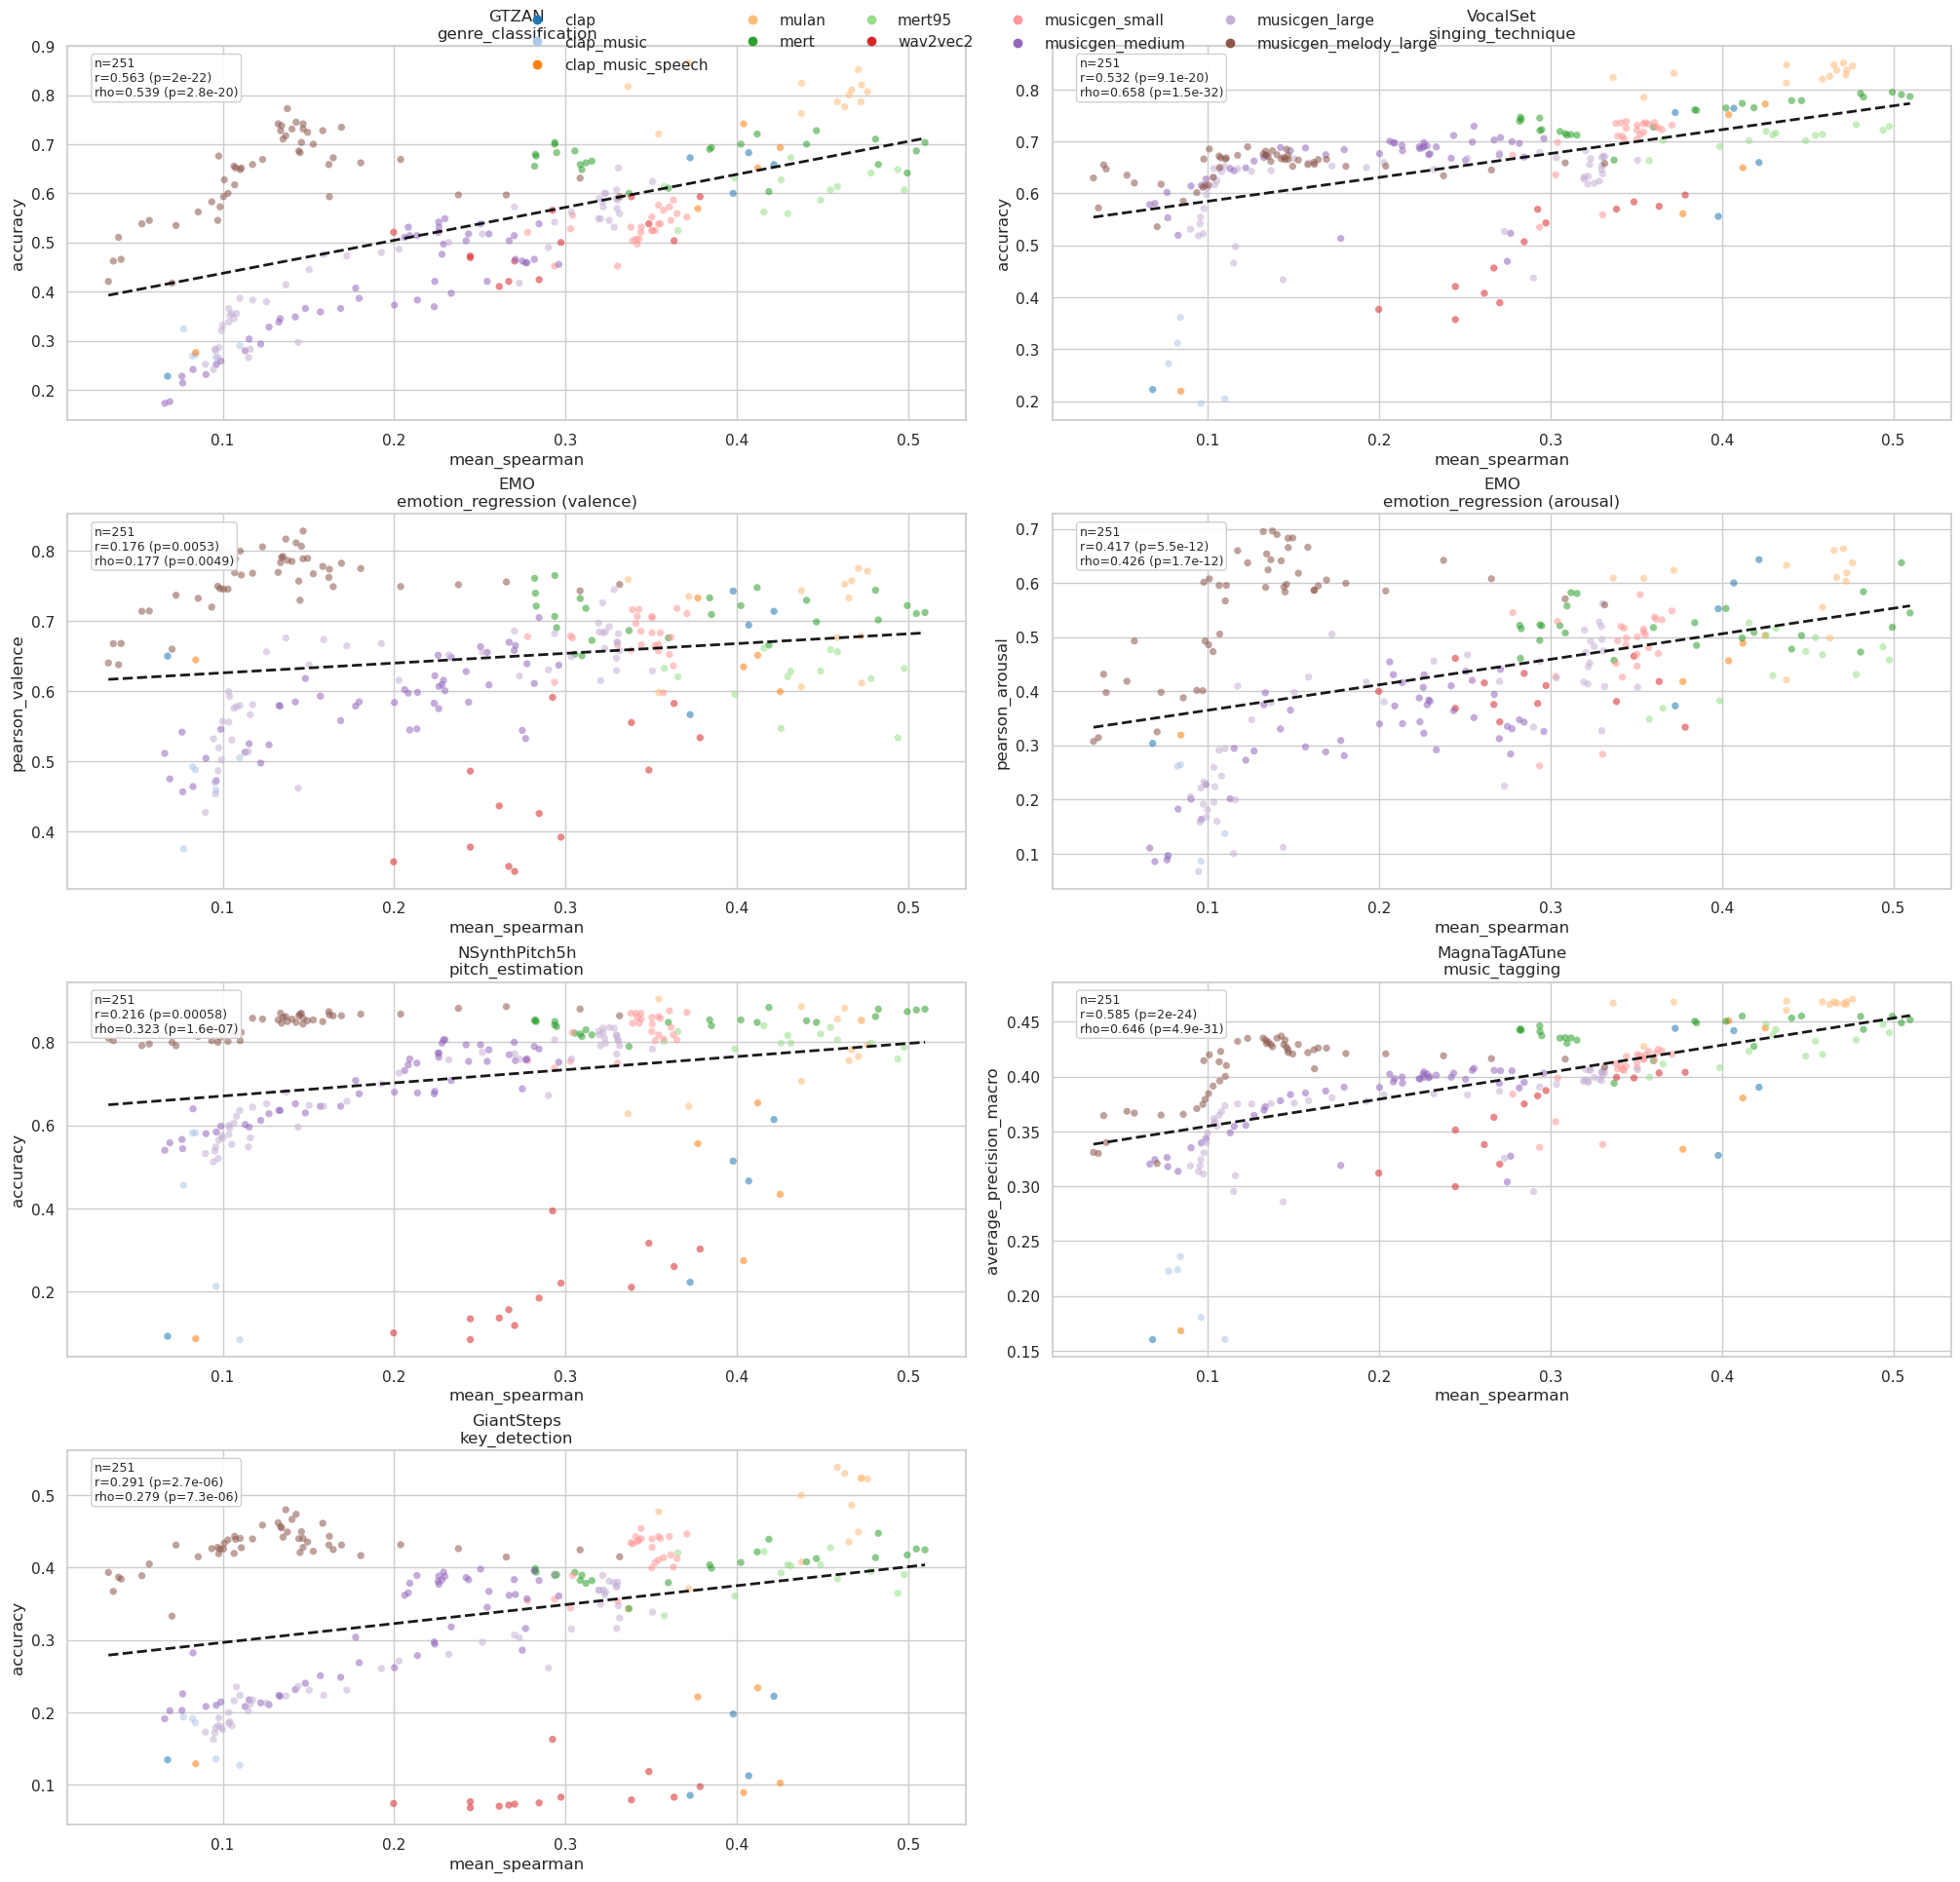

In [4]:
display(Markdown('## All Models: Alignment vs. Downstream Performance'))
n_tasks = max(len(task_order), 1)
n_cols = 2 if n_tasks > 1 else 1
n_rows = int(np.ceil(n_tasks / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 4.8 * n_rows), constrained_layout=True)
axes = np.atleast_1d(axes).ravel()

for ax, dataset_task in zip(axes, task_order):
    subset = plot_layerwise[plot_layerwise['dataset_task'] == dataset_task].copy()
    title_text = str(subset['dataset_task_display'].iloc[0]) if len(subset) else str(dataset_task)
    title_dataset, title_task = title_text.split(' / ', 1)
    if len(subset) == 0:
        ax.set_title(f'{title_dataset}\n{title_task}')
        ax.set_xlabel(score_label)
        ax.set_ylabel('Probe performance')
        continue

    for model_name in model_order:
        model_subset = subset[subset['model_name'] == model_name]
        if len(model_subset) == 0:
            continue
        ax.scatter(
            model_subset['alignment_score'],
            model_subset['downstream_score'],
            color=palette[model_name],
            s=28,
            alpha=0.55,
            edgecolors='none',
        )

    x = subset['alignment_score'].to_numpy(dtype=float)
    y = subset['downstream_score'].to_numpy(dtype=float)
    if len(subset) >= 3 and np.unique(x).size >= 2:
        slope, intercept = np.polyfit(x, y, deg=1)
        x_line = np.linspace(float(np.min(x)), float(np.max(x)), 100)
        y_line = slope * x_line + intercept
        pearson_task = pearsonr(x, y)
        spearman_task = spearmanr(x, y)
        ax.plot(x_line, y_line, color='black', linestyle='--', linewidth=2.0, alpha=0.9)
        ax.text(
            0.03,
            0.97,
            (
                f'n={len(subset)}\n'
                f'r={pearson_task.statistic:.3f} (p={pearson_task.pvalue:.2g})\n'
                f'rho={spearman_task.statistic:.3f} (p={spearman_task.pvalue:.2g})'
            ),
            transform=ax.transAxes,
            ha='left',
            va='top',
            fontsize=9,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='0.8', alpha=0.92),
        )

    metric_name = str(subset['downstream_metric_name'].iloc[0])
    ax.set_title(f'{title_dataset}\n{title_task}')
    ax.set_xlabel(score_label)
    ax.set_ylabel(metric_name)

for ax in axes[len(task_order):]:
    ax.axis('off')

legend_handles = [
    Line2D([0], [0], marker='o', linestyle='', label=model_name, color=palette[model_name], markersize=6)
    for model_name in model_order
]
fig.legend(handles=legend_handles, loc='upper center', ncol=min(5, len(legend_handles)), frameon=False)
plt.show()

